---
title: "Bring your own observations"
subtitle: "Prepare CHIRPS v3.0 seasonal totals and give them to PyCPT"
description: "Build an OND predictand file from a local CHIRPS v3.0 archive, load it through PyCPT's local_predictand_file option, verify it, and compare it with the catalog's CHIRPS v2.0."
execute:
  enabled: false
---

The catalog offers a fixed list of observation datasets. PyCPT's `download_data`
also accepts a local predictand file in place of a catalog name; IRI's operational
template exposes this as `local_predictand_file`.

This chapter prepares OND rainfall totals from a local **CHIRPS v3.0** archive,
the observation product used by the case studies, and passes them to PyCPT. It
then checks the result twice: against the observation file of the
[Fit & diagnose](../chapters/fit-diagnose-2023.qmd) case, and against the CHIRPS
v2.0 data downloaded in [chapter 2](02-getting-data.ipynb).

::: {.callout-note title="What you need to run this page"}
The full PyCPT environment, the case folder from chapters 1 and 2, and a local
CHIRPS v3.0 file of 3-month rainfall totals (step 2 describes the one used here;
point `chirps3_file` at your own copy). The country boundary comes from Natural
Earth through Cartopy, which downloads it the first time it is used.
:::

## 1. Repeat the case settings

The settings are unchanged. This time `force_download=False`: chapter 2 already
downloaded the model data for exactly this question into this case folder, so
reusing those files is correct. Chapter 1 explains why that is only safe when the
folder and the question match.

In [1]:
from pathlib import Path
import datetime as dt
import json
import os
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shapely
import xarray as xr
import cartopy.io.shapereader as shapereader
import pycpt

repo = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pycpt_tutorial").is_dir()), None)
if repo is None:
    raise FileNotFoundError("Run this notebook inside the tutorial repository or kit.")
sys.path.insert(0, str(repo))
from pycpt_tutorial.country_grid import aggregate_country_rainfall, training_complete_mask
from pycpt_tutorial.export import save_netcdf
from pycpt_tutorial import figures
figures.use_style()

MOS = "CCA"
predictor_names = ["CFSv2.PRCP"]
download_args = {
    "fdate": dt.datetime(2023, 9, 1),
    "target": "Oct-Dec",
    "target_first_year": 1991,
    "target_final_year": 2020,
    "predictor_extent": {"west": 85, "east": 155, "south": -20, "north": 20},
    "predictand_extent": {"west": 94, "east": 142, "south": -12, "north": 7},
}
force_download = False

case_dir = Path.home() / "PyCPT" / "indonesia-ond-2023-sep-init"
domain_dir = pycpt.setup(case_dir, download_args["predictor_extent"])
training_years = list(range(download_args["target_first_year"], download_args["target_final_year"] + 1))

Input data will be saved in ~/PyCPT/indonesia-ond-2023-sep-init/85W-155E_to_-20S-20N/data
Figures will be saved in ~/PyCPT/indonesia-ond-2023-sep-init/85W-155E_to_-20S-20N/figures
Output will be saved in ~/PyCPT/indonesia-ond-2023-sep-init/85W-155E_to_-20S-20N/output


## 2. Open the local CHIRPS v3.0 file

The file used here holds **3-month rainfall totals** at the native CHIRPS v3.0
resolution of 0.05°, one window every dekad from 1981 to 2025. It was built from
the CHIRPS v3.0 global dekadal data distributed by the
[Climate Hazards Center](https://www.chc.ucsb.edu/data/chirps3). The cell prints
the file's own description rather than restating it.

In [2]:
chirps3_file = Path(os.environ.get(
    "CHIRPS3_MONTH3_FILE",
    "/mnt/e/temp/chirps/rolling_dekad/wld_cli_chirps3_month3_bydekad_1981_2025.nc"))
source = xr.open_dataset(chirps3_file)

print(f"File size: {chirps3_file.stat().st_size / 1e9:.1f} GB")
for key in ["title", "summary", "source", "version", "comment", "history"]:
    print(f"{key:>8}: {source.attrs.get(key)}")
print()
print("precip units:", source.precip.attrs.get("units"),
      "| grid:", f"{source.sizes['lat']} x {source.sizes['lon']}",
      "| time steps:", source.sizes["time"])

File size: 24.3 GB
   title: CHIRPS Version 3.0 - 3-month precipitation accumulation, rolling by dekad
 summary: 3-month (9 dekad) rolling precipitation accumulation derived from CHIRPS v3.0 dekadal data, advancing one dekad at a time.
  source: CHIRPS v3.0 global dekad, Climate Hazards Center, UC Santa Barbara
 version: Version 3.0
 comment: Time stamp denotes the first day of the last dekad in the accumulation window; time_bnds spans the whole window.
 history: 2026-08-24T21:53:55 compute_rolling_multi(): 9-dekad rolling sum of wld_cli_chirps3_dekad_1981_2025.nc (nan_policy=strict)

precip units: mm | grid: 2400 x 7200 | time steps: 1612


## 3. Pick the OND windows by their bounds

The file's comment says each time stamp is the first day of the *last* dekad in
the window, and `time_bnds` gives the whole window. An OND total is therefore
stamped 21 December. Rather than trusting that reasoning, the cell selects those
stamps and checks that every window runs from 1 October to 1 January (end
exclusive).

In [3]:
times = pd.DatetimeIndex(source.time.values)
stamps = [int(np.flatnonzero((times.year == y) & (times.month == 12) & (times.day == 21))[0])
          for y in training_years]
bounds = pd.DataFrame(source.time_bnds.isel(time=stamps).values, columns=["start", "end (exclusive)"])
bounds.index = training_years

expected_start = pd.to_datetime([f"{y}-10-01" for y in training_years])
expected_end = pd.to_datetime([f"{y + 1}-01-01" for y in training_years])
assert (bounds["start"].values == expected_start.values).all()
assert (bounds["end (exclusive)"].values == expected_end.values).all()
print(f"All {len(stamps)} windows span 1 October to 31 December of their year.")
bounds.iloc[[0, 1, -1]]

All 30 windows span 1 October to 31 December of their year.


,start,end (exclusive)
1991,1991-10-01,1992-01-01
1992,1992-10-01,1993-01-01
2020,2020-10-01,2021-01-01


## 4. Read only the predictand box

The file is large, but only 30 time steps inside the predictand box are needed.
xarray reads just that subset from disk.

In [4]:
box = download_args["predictand_extent"]
start = time.monotonic()
native = (source.precip
          .sel(lon=slice(box["west"], box["east"]), lat=slice(box["south"], box["north"]))
          .isel(time=stamps)
          .load())
print(f"Read {dict(native.sizes)} in {time.monotonic() - start:.0f} s")
print(f"Longitude {float(native.lon.min()):.3f} to {float(native.lon.max()):.3f}, "
      f"latitude {float(native.lat.min()):.3f} to {float(native.lat.max()):.3f}")
print("Negative values:", int((native < 0).sum()), "| missing values:", int(native.isnull().sum()))

Read {'time': 30, 'lat': 380, 'lon': 960} in 8 s
Longitude 94.025 to 141.975, latitude -11.975 to 6.975


Negative values: 0 | missing values: 7886640


## 5. Aggregate 0.05° to the 0.25° grid over Indonesia

The predictand grid matches the case studies: 0.25° cells whose centres run from
94.125°E and 6.875°N. Each 0.25° cell holds 5 × 5 native pixels. The case studies
used the tutorial's helper `aggregate_country_rainfall`, which:

- keeps only native pixels whose centres fall inside Indonesia,
- averages them with cos(latitude) area weights, so a cell value is a mean
  rainfall depth, not a sum over pixels,
- keeps a cell only if at least 99% of its Indonesian land weight has data.

The boundary is the Natural Earth 1:10m country polygon for Indonesia (`ADM0_A3`
= `IDN`).

In [5]:
records = shapereader.Reader(shapereader.natural_earth("10m", "cultural", "admin_0_countries")).records()
indonesia = next(r.geometry for r in records if r.attributes["ADM0_A3"] == "IDN")
shapely.prepare(indonesia)

lon2d, lat2d = np.meshgrid(native.lon, native.lat)
country = xr.DataArray(shapely.contains_xy(indonesia, lon2d, lat2d), dims=("lat", "lon"),
                       coords={"lat": native.lat, "lon": native.lon})
print(f"Native pixels inside Indonesia: {int(country.sum()):,} of {country.size:,}")

centres_y = box["south"] + 0.125 + np.arange(76) * 0.25
centres_x = box["west"] + 0.125 + np.arange(192) * 0.25
seasons = []
for i in range(native.sizes["time"]):
    block = aggregate_country_rainfall(native.isel(time=i, drop=True), country, 5, minimum_coverage=0.99)
    seasons.append(block.precipitation.rename({"lat": "Y", "lon": "X"})
                   .assign_coords(Y=centres_y, X=centres_x).sortby("Y", ascending=False))

Native pixels inside Indonesia: 61,192 of 364,800


The case studies kept only cells with data in every training season. The same
rule is applied here, so the two results can be compared directly.

The target dates `T`, `Ti` and `Tf` are copied from the CFSv2 hindcasts downloaded
in chapter 2, which makes the alignment of model and observation seasons explicit.
The hindcasts' initialization date `S` is **not** copied: observations have no
initialization, and PyCPT's own downloaded observations carry no `S`. This matters
in practice. A first version of this file inherited `S` from the model time axis;
it passed cptio's checks, but in this environment the fit in chapter 4 then failed
while reading CPT's output, because CPT 17.8.3 wrote the initialization date without
a time and cptio 1.4.0 refuses such dates.

In [6]:
hindcasts = xr.open_dataset(domain_dir / "data" / "CFSv2.PRCP.nc")
model_time = pd.Index(hindcasts["T"].values, name="T")
assert (model_time.year == np.array(training_years)).all()

chirps3 = (xr.concat(seasons, dim=model_time)
           .assign_coords(Ti=("T", hindcasts["Ti"].values), Tf=("T", hindcasts["Tf"].values)))
assert "S" not in chirps3.coords
complete = training_complete_mask(chirps3, training_years)
chirps3 = chirps3.where(complete).transpose("T", "Y", "X").rename("precipitation")
chirps3.attrs = {"units": "mm", "missing": -999.0,
                 "long_name": "CHIRPS v3.0 OND rainfall total, Indonesia land, 0.25 degree"}

print(f"Cells with data in all {len(training_years)} seasons: {int(complete.sum())}")
print("Season of first value:", str(chirps3["Ti"].values[0])[:10], "to", str(chirps3["Tf"].values[0])[:10])
print(f"Range: {float(chirps3.min()):.1f} to {float(chirps3.max()):.1f} mm")

Cells with data in all 30 seasons: 3240
Season of first value: 1991-10-01 to 1991-12-31
Range: 5.8 to 3470.0 mm


## 6. Save the file and give it to PyCPT

`download_data` accepts a local file ending in `.nc` (opened with xarray) or
`.tsv` (CPT text). It takes the **first data variable** in the file, so the file
should contain only the rainfall variable. The file name is chosen so it cannot
collide with PyCPT's own download names.

`download_data` itself does not check the file. The check happens later, when
`cptcore` starts a fit and calls `cptio`'s `is_valid_cptv10_xyt` on the
predictand. In the installed cptio 1.4.0 that check requires, among other things:

- `T`, `Y` and `X` coordinates, and only coordinates from CPT's list
  (`T`, `Ti`, `Tf`, `S`, `X`, `Y` and a few others);
- `Ti` and `Tf` together or not at all;
- a `units` attribute;
- a `missing` attribute holding a number, the value CPT writes in place of NaN.

The first version of this chapter left out `missing`, and the fit in chapter 4
stopped with that assertion. The attribute is set above, and the cell after the
load runs the same check that `cptcore` will run.

In [7]:
local_predictand_file = domain_dir / "data" / "local-CHIRPS3-OND-1991-2020.nc"
save_netcdf(chirps3.to_dataset(), local_predictand_file, overwrite=True,
            metadata={"source_file": chirps3_file.name,
                      "aggregation": "cos-latitude weighted mean of Indonesian 0.05 degree pixels per 0.25 degree cell; at least 99% country-land coverage",
                      "boundary": "Natural Earth 1:10m admin_0_countries, ADM0_A3=IDN",
                      "training_years": "1991-2020"})

Y, hindcast_data, forecast_data = pycpt.download_data(
    "CHIRPS3 (local)", local_predictand_file, predictor_names,
    download_args, domain_dir, force_download)
print("Data variable PyCPT took:", Y.name, "| shape:", dict(Y.sizes))

Reusing already-downloaded CFSv2.PRCP_f2023

Using local observed predictand dataset
Reusing already-downloaded CFSv2.PRCP

Data variable PyCPT took: precipitation | shape: {'T': 30, 'Y': 76, 'X': 192}


In [8]:
from cptio.utilities.verify import is_valid_cptv10_xyt

is_valid_cptv10_xyt(Y)
print("Passes cptio's CPTv10 check, the one cptcore runs before fitting.")
print("units:", Y.attrs["units"], "| missing:", Y.attrs["missing"], "| coordinates:", sorted(Y.coords))

Passes cptio's CPTv10 check, the one cptcore runs before fitting.
units: mm | missing: -999.0 | coordinates: ['T', 'Tf', 'Ti', 'X', 'Y']


In [9]:
pycpt.summarize_available_years(predictor_names, "CHIRPS3 (local)", download_args,
                                Y, hindcast_data, forecast_data)

,CHIRPS3 (local),CFSv2.PRCP
1991,ok,ok
1992,ok,ok
1993,ok,ok
1994,ok,ok
1995,ok,ok
1996,ok,ok
1997,ok,ok
1998,ok,ok
1999,ok,ok
2000,ok,ok


,CFSv2.PRCP
2023,ok


## 7. Check against the Fit & diagnose observations

The case study prepared its observations with a separate research script from the
same CHIRPS v3.0 archive. If both routes are right, the arrays must be identical.

In [10]:
case_y_file = repo / "docs/data/fitting-2023/OND-Y.nc"
case_y = xr.open_dataset(case_y_file).precipitation.load()

same_cells = bool((Y.notnull() == case_y.notnull()).all())
largest_gap = float(np.nanmax(np.abs(Y.transpose("T", "Y", "X").values - case_y.transpose("T", "Y", "X").values)))
print("Same missing-value pattern:", same_cells)
print("Same target dates:", bool((Y["T"].values == case_y["T"].values).all()))
print(f"Largest difference: {largest_gap} mm")

Same missing-value pattern: True
Same target dates: True
Largest difference: 0.0 mm


The predictand built here is the Fit & diagnose predictand, value for value. Any
difference in the next chapter's fits will therefore come from the predictor:
chapter 2 measured how PyCPT's CFSv2 totals differ from the case study's.

## 8. CHIRPS v3.0 or v2.0: does the choice matter?

Chapter 2 downloaded the catalog's CHIRPS v2.0 (`UCSB.PRCP`) on the same 0.25°
grid. The two fields are compared only on cells where **both** have data in every
training season. Two things differ
at once: the product version, and the way each 0.25° value was made (the Data
Library's 0.25° CHIRPS v2.0 grid versus the Indonesia-only average built here).
The comparison shows the combined effect; it does not separate them.

In [11]:
ucsb = xr.open_dataset(domain_dir / "data" / "UCSB.PRCP.nc").prcp
assert np.allclose(ucsb["X"], Y["X"]) and np.allclose(ucsb["Y"], Y["Y"])
assert (ucsb["T"].values == Y["T"].values).all()

v3_all = Y.transpose("T", "Y", "X")
v2_all = ucsb.transpose("T", "Y", "X")
v3_complete = v3_all.notnull().all("T")
both = v3_complete & v2_all.notnull().all("T")
shared_cells = int(both.sum())
print(f"CHIRPS v3.0 cells kept above: {int(v3_complete.sum())}")
print(f"Of those, cells where CHIRPS v2.0 also has data in every season: {shared_cells}")
print(f"Cells with v3.0 data but no complete v2.0 series: {int((v3_complete & ~both).sum())}")

v3 = v3_all.where(both)
v2 = v2_all.where(both)
weights = np.cos(np.deg2rad(v3["Y"])) * both
national_v3 = v3.weighted(weights).mean(("Y", "X"))
national_v2 = v2.weighted(weights).mean(("Y", "X"))
difference = v3 - v2

summary = pd.Series({
    "national mean OND total, v3.0 (mm)": float(national_v3.mean()),
    "national mean OND total, v2.0 (mm)": float(national_v2.mean()),
    "mean difference v3.0 - v2.0 (mm)": float((national_v3 - national_v2).mean()),
    "correlation of yearly national totals": float(np.corrcoef(national_v3, national_v2)[0, 1]),
    "median absolute cell difference (mm)": float(np.nanmedian(np.abs(difference))),
    "95th percentile absolute cell difference (mm)": float(np.nanpercentile(np.abs(difference), 95)),
}).round(3)
summary.to_frame("value")

CHIRPS v3.0 cells kept above: 3240
Of those, cells where CHIRPS v2.0 also has data in every season: 3091
Cells with v3.0 data but no complete v2.0 series: 149


,value
"national mean OND total, v3.0 (mm)",781.289
"national mean OND total, v2.0 (mm)",780.697
mean difference v3.0 - v2.0 (mm),0.592
correlation of yearly national totals,0.986
median absolute cell difference (mm),73.275
95th percentile absolute cell difference (mm),267.897


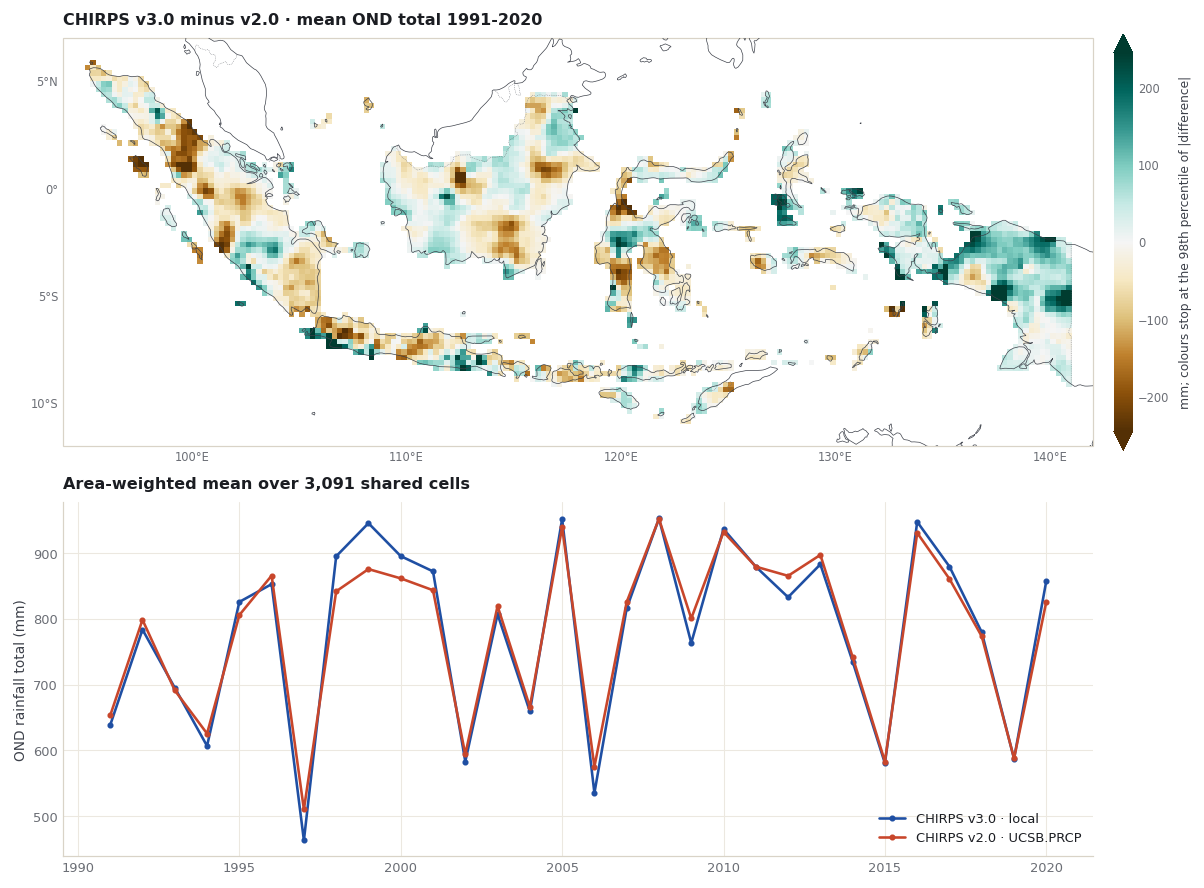

In [12]:
fig, grid = figures.stacked([figures.map_height(figures.extent_of(box)), 3.2])
mean_diff = difference.mean("T")
limit = float(np.nanpercentile(np.abs(mean_diff), 98))
ax = figures.map_axes(fig, grid[0, 0], figures.extent_of(box))
image = figures.draw_field(ax, mean_diff, cmap="BrBG", vmin=-limit, vmax=limit)
ax.set_title("CHIRPS v3.0 minus v2.0 · mean OND total 1991-2020")
figures.colorbar(fig, image, ax, "mm; colours stop at the 98th percentile of |difference|", extend="both")

ax = fig.add_subplot(grid[1, 0])
years = v3["T"].dt.year
ax.plot(years, national_v3, marker="o", markersize=3, label="CHIRPS v3.0 · local")
ax.plot(years, national_v2, marker="o", markersize=3, label="CHIRPS v2.0 · UCSB.PRCP")
ax.set_title(f"Area-weighted mean over {shared_cells:,} shared cells")
ax.set_ylabel("OND rainfall total (mm)")
ax.legend(loc="lower right")
plt.show()

Read the numbers above before choosing. A choice of observations changes what the
calibration learns and what it is scored against, so it should be made for a
documented reason, such as the product a national service already uses, and not
by comparing which one gives better skill.

## What you have now

- A local CHIRPS v3.0 OND predictand built from a documented archive, with each
  window checked by its time bounds.
- The file loaded through PyCPT's `local_predictand_file` option, with every
  training year present.
- Proof that it equals the Fit & diagnose predictand.
- A measured comparison with the catalog's CHIRPS v2.0.

The next chapter fits CCA with `evaluate_models` on these inputs and compares the
result with the Fit & diagnose case.

## References {.unnumbered .reference-section}

1. IRI. *PyCPT operational seasonal notebook* (`Operations/pycpt-operational.ipynb`). iri-pycpt/notebooks, commit 1c97531. <https://github.com/iri-pycpt/notebooks/blob/1c975316910b9e047ce685d9b8cdefb2c4b73551/Operations/pycpt-operational.ipynb>
2. IRI. *PyCPT 2.10.4 source: `pycpt/src/pycpt/notebook.py`* (`setup`, `download_data`, `summarize_available_years`, `evaluate_models` and the plotting functions). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/blob/084bb5c380c200b5f65f11ba224a965547b91da1/pycpt/src/pycpt/notebook.py>
3. IRI. *PyCPT 2.10.4 source: `cpt-io/src/cptio/utilities/verify.py`* (`is_valid_cptv10_xyt`). Tag pycpt-2.10.4, commit 084bb5c. <https://github.com/iri-pycpt/pycpt/blob/084bb5c380c200b5f65f11ba224a965547b91da1/cpt-io/src/cptio/utilities/verify.py>
4. Climate Hazards Center, UC Santa Barbara. *CHIRPS: Rainfall Estimates from Rain Gauge and Satellite Observations* (CHIRPS version 3.0 page). <https://www.chc.ucsb.edu/data/chirps3>
5. Funk, C., Peterson, P., Landsfeld, M., et al. (2014). *A quasi-global precipitation time series for drought monitoring*. U.S. Geological Survey Data Series 832. <https://doi.org/10.3133/ds832>
6. IRI Data Library. *UCSB CHIRPS version 2.0*. <https://iridl.ldeo.columbia.edu/SOURCES/.UCSB/.CHIRPS/.v2p0/> Browsing Data Library pages requires signing in (checked 10 November 2026); PyCPT's data requests in this tutorial succeeded without a key.
7. Funk, C., Peterson, P., Landsfeld, M., et al. (2015). The climate hazards infrared precipitation with stations: a new environmental record for monitoring extremes. *Scientific Data*, 2, 150066. <https://doi.org/10.1038/sdata.2015.66>
8. Natural Earth. *Admin 0: Countries*, 1:10m cultural vectors. <https://www.naturalearthdata.com/downloads/10m-cultural-vectors/10m-admin-0-countries/>
9. Shapely. *shapely.contains_xy*. <https://shapely.readthedocs.io/en/stable/reference/shapely.contains_xy.html>
10. SciTools. *Cartopy* (documentation). <https://scitools.org.uk/cartopy/docs/latest/>